imports

In [62]:
import joblib
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold, cross_validate

print("Libraries imported successfully!")

Libraries imported successfully!


loading data

In [4]:
df = pd.read_csv("../data/raw/ai4i2020.csv")

print("Dataset shape:", df.shape)

Dataset shape: (10000, 14)


defining features

In [5]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target = "Machine failure"

X = df[features].copy()
y = df[target].copy()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(8000, 6)
(2000, 6)


In [7]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

 below dummy classifiesr

In [8]:
dummy_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]
)

dummy_pipeline.fit(X_train, y_train)

dummy_pred = dummy_pipeline.predict(X_test)

In [9]:
print("DUMMY CLASSIFIER")

print("Accuracy :", accuracy_score(y_test, dummy_pred))
print("Precision:", precision_score(y_test, dummy_pred, zero_division=0))
print("Recall   :", recall_score(y_test, dummy_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, dummy_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dummy_pred))

DUMMY CLASSIFIER
Accuracy : 0.966
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0

Confusion Matrix:
[[1932    0]
 [  68    0]]


0% machine which are failed are detected in our dummy model

MODEL 1- logistic regression

In [10]:
class_weight="balanced"

In [11]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).B

predictions

In [12]:
logistic_pred = logistic_pipeline.predict(X_test)

logistic_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

below is evolution of logistic regression

In [13]:
print("LOGISTIC REGRESSION")

print("Accuracy :", accuracy_score(y_test, logistic_pred))
print("Precision:", precision_score(y_test, logistic_pred))
print("Recall   :", recall_score(y_test, logistic_pred))
print("F1 Score :", f1_score(y_test, logistic_pred))

print(
    "ROC-AUC  :",
    roc_auc_score(y_test, logistic_prob)
)

print(
    "PR-AUC   :",
    average_precision_score(y_test, logistic_prob)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_pred))

LOGISTIC REGRESSION
Accuracy : 0.8245
Precision: 0.14177215189873418
Recall   : 0.8235294117647058
F1 Score : 0.24190064794816415
ROC-AUC  : 0.9069540859822189
PR-AUC   : 0.38176196610560775

Confusion Matrix:
[[1593  339]
 [  12   56]]


In [14]:
print(
    classification_report(
        y_test,
        logistic_pred,
        target_names=["Normal", "Failure"]
    )
)

              precision    recall  f1-score   support

      Normal       0.99      0.82      0.90      1932
     Failure       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



abiut 82% of failed machine are detected which is much much better than our dummy model in logestic regression.
But Failure Precision = 0.14 ⚠️
This is low.
Precision asks:
Out of all machines that our model called "failure", how many were actually failures?

Only approximately 14%.
So Logistic Regression is generating many false alarms.

In [15]:
print("LOGISTIC REGRESSION")

print("Accuracy :", accuracy_score(y_test, logistic_pred))
print("Precision:", precision_score(y_test, logistic_pred))
print("Recall   :", recall_score(y_test, logistic_pred))
print("F1 Score :", f1_score(y_test, logistic_pred))
print("ROC-AUC  :", roc_auc_score(y_test, logistic_prob))
print("PR-AUC   :", average_precision_score(y_test, logistic_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_pred))

LOGISTIC REGRESSION
Accuracy : 0.8245
Precision: 0.14177215189873418
Recall   : 0.8235294117647058
F1 Score : 0.24190064794816415
ROC-AUC  : 0.9069540859822189
PR-AUC   : 0.38176196610560775

Confusion Matrix:
[[1593  339]
 [  12   56]]


RANDOM FOREST
Random Forest is especially useful here because relationships among RPM, torque, temperature and wear can be nonlinear.

In [16]:
from sklearn.ensemble import RandomForestClassifier

In [17]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=10,
                min_samples_leaf=3,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).B

Random Forest predictions

In [18]:
rf_pred = rf_pipeline.predict(X_test)

rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

In [19]:
print("RANDOM FOREST")

print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))
print("ROC-AUC  :", roc_auc_score(y_test, rf_prob))
print("PR-AUC   :", average_precision_score(y_test, rf_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["Normal", "Failure"]
    )
)

RANDOM FOREST
Accuracy : 0.9635
Precision: 0.4789915966386555
Recall   : 0.8382352941176471
F1 Score : 0.6096256684491979
ROC-AUC  : 0.9656634392887591
PR-AUC   : 0.6878533189771349

Confusion Matrix:
[[1870   62]
 [  11   57]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.97      0.98      1932
     Failure       0.48      0.84      0.61        68

    accuracy                           0.96      2000
   macro avg       0.74      0.90      0.80      2000
weighted avg       0.98      0.96      0.97      2000



CHECKING OVERFITING OF DATA

In [20]:
rf_train_pred = rf_pipeline.predict(X_train)

print("Training F1:",
      f1_score(y_train, rf_train_pred))

print("Testing F1:",
      f1_score(y_test, rf_pred))

print("Training Recall:",
      recall_score(y_train, rf_train_pred))

print("Testing Recall:",
      recall_score(y_test, rf_pred))

Training F1: 0.7221476510067114
Testing F1: 0.6096256684491979
Training Recall: 0.992619926199262
Testing Recall: 0.8382352941176471


COMPARISION TABLE B/W dummy,logistic regression and random forest

In [21]:
results = pd.DataFrame({
    "Model": [
        "Dummy",
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, dummy_pred),
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, dummy_pred, zero_division=0),
        precision_score(y_test, logistic_pred),
        precision_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, dummy_pred),
        recall_score(y_test, logistic_pred),
        recall_score(y_test, rf_pred)
    ],

    "F1": [
        f1_score(y_test, dummy_pred),
        f1_score(y_test, logistic_pred),
        f1_score(y_test, rf_pred)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1
0,Dummy,0.9660,0.000000,0.000000,0.000000
1,Logistic Regression,0.8245,0.141772,0.823529,0.241901
2,Random Forest,0.9635,0.478992,0.838235,0.609626


XGBOOST

In [22]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("scale_pos_weight:", scale_pos_weight)

scale_pos_weight: 28.52029520295203


XG BOOST MODEL

In [23]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=scale_pos_weight,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("XGBoost pipeline created successfully!")

XGBoost pipeline created successfully!


Now use 5-fold Stratified Cross-Validation

In [24]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

Compare Random Forest and XGBoost

In [25]:
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

RANDOM FOREST

In [26]:
rf_cv = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

XGBOOST

In [27]:
xgb_cv = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

COMPARISION TABLE FOR RANDOM FOREST AND XGBOOST

In [28]:
cv_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],

    "Precision Mean": [
        rf_cv["test_precision"].mean(),
        xgb_cv["test_precision"].mean()
    ],

    "Precision Std": [
        rf_cv["test_precision"].std(),
        xgb_cv["test_precision"].std()
    ],

    "Recall Mean": [
        rf_cv["test_recall"].mean(),
        xgb_cv["test_recall"].mean()
    ],

    "Recall Std": [
        rf_cv["test_recall"].std(),
        xgb_cv["test_recall"].std()
    ],

    "F1 Mean": [
        rf_cv["test_f1"].mean(),
        xgb_cv["test_f1"].mean()
    ],

    "F1 Std": [
        rf_cv["test_f1"].std(),
        xgb_cv["test_f1"].std()
    ],

    "ROC-AUC Mean": [
        rf_cv["test_roc_auc"].mean(),
        xgb_cv["test_roc_auc"].mean()
    ],

    "PR-AUC Mean": [
        rf_cv["test_pr_auc"].mean(),
        xgb_cv["test_pr_auc"].mean()
    ]
})

cv_results.round(4)

,Model,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,PR-AUC Mean
0,Random Forest,0.4744,0.0087,0.8154,0.0270,0.5996,0.0106,0.9674,0.6851
1,XGBoost,0.6601,0.0423,0.7861,0.0316,0.7166,0.0298,0.9715,0.7625


EXPALINATION OF TABLE
Random Forest
Recall = 81.54%
Precision = 47.44%

            vs

XGBoost
Recall = 78.61%
Precision = 66.01%

So XGBoost loses roughly 3 percentage points of recall, but gains roughly 19 percentage points of precision and improves F1 from 0.60 → 0.72.
For this project, we should now tune XGBoost on the training set, then tune its classification threshold. Threshold tuning may allow us to recover some recall while retaining much of XGBoost's precision advantage.

Next: tune XGBoost correctly
We should not manually try dozens of combinations against the test set. We'll use RandomizedSearchCV with the same 5-fold stratified CV.

In [29]:
from sklearn.model_selection import RandomizedSearchCV

DEFINING THE SEARCH SPACE

In [30]:
xgb_param_grid = {
    "classifier__n_estimators": [200, 300, 400, 500, 600],
    
    "classifier__max_depth": [2, 3, 4, 5, 6],
    
    "classifier__learning_rate": [
        0.01, 0.03, 0.05, 0.08, 0.1
    ],
    
    "classifier__subsample": [
        0.7, 0.8, 0.9, 1.0
    ],
    
    "classifier__colsample_bytree": [
        0.7, 0.8, 0.9, 1.0
    ],
    
    "classifier__min_child_weight": [
        1, 3, 5, 7
    ],
    
    "classifier__gamma": [
        0, 0.1, 0.2, 0.5
    ],
    
    "classifier__reg_alpha": [
        0, 0.01, 0.1, 0.5
    ],
    
    "classifier__reg_lambda": [
        0.5, 1, 2, 5
    ]
}

Run RandomizedSearchCV

In [32]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_grid,
    n_iter=40,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [33]:
xgb_search.fit(X_train, y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': [0.7, 0.8, ...], 'classifier__gamma': [0, 0.1, ...], 'classifier__learning_rate': [0.01, 0.03, ...], 'classifier__max_depth': [2, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",40
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than 

In [34]:
print("Best CV PR-AUC:")
print(xgb_search.best_score_)

print("\nBest Parameters:")

for parameter, value in xgb_search.best_params_.items():
    print(parameter, ":", value)

Best CV PR-AUC:
0.777284934621771

Best Parameters:
classifier__subsample : 1.0
classifier__reg_lambda : 0.5
classifier__reg_alpha : 0.5
classifier__n_estimators : 600
classifier__min_child_weight : 5
classifier__max_depth : 6
classifier__learning_rate : 0.05
classifier__gamma : 0
classifier__colsample_bytree : 0.8


In [35]:
best_xgb = xgb_search.best_estimator_

Check the tuned model with cross-validation
Even though RandomizedSearchCV gives us its best score, let's collect several metrics for the selected estimator:

In [36]:
best_xgb_cv = cross_validate(
    best_xgb,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("TUNED XGBOOST CROSS-VALIDATION")
print("--------------------------------")

print(
    "Precision:",
    best_xgb_cv["test_precision"].mean(),
    "+/-",
    best_xgb_cv["test_precision"].std()
)

print(
    "Recall:",
    best_xgb_cv["test_recall"].mean(),
    "+/-",
    best_xgb_cv["test_recall"].std()
)

print(
    "F1:",
    best_xgb_cv["test_f1"].mean(),
    "+/-",
    best_xgb_cv["test_f1"].std()
)

print(
    "ROC-AUC:",
    best_xgb_cv["test_roc_auc"].mean(),
    "+/-",
    best_xgb_cv["test_roc_auc"].std()
)

print(
    "PR-AUC:",
    best_xgb_cv["test_pr_auc"].mean(),
    "+/-",
    best_xgb_cv["test_pr_auc"].std()
)

TUNED XGBOOST CROSS-VALIDATION
--------------------------------
Precision: 0.6663073030229616 +/- 0.04546879116591656
Recall: 0.7713804713804715 +/- 0.036889820672868265
F1: 0.7139897988378173 +/- 0.034450116479502454
ROC-AUC: 0.9690017557100539 +/- 0.015368029938477527
PR-AUC: 0.777284934621771 +/- 0.05678010754859352


For our predictive-maintenance project, the next important step is threshold selection using training data only. We can potentially recover recall without retraining the model.
Step 1 — Generate out-of-fold probabilities

In [37]:
from sklearn.model_selection import cross_val_predict

In [38]:
oof_prob = cross_val_predict(
    best_xgb,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF predictions created:", len(oof_prob))

OOF predictions created: 8000


above
Why are we doing this?
Every training observation receives a probability from a model that did not train on that particular observation.
That's much safer for choosing a threshold

Step 2 — Test different thresholds

In [39]:
threshold_results = []

for threshold in np.arange(0.10, 0.81, 0.05):

    predictions = (oof_prob >= threshold).astype(int)

    precision = precision_score(
        y_train,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_train,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_train,
        predictions,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Precision,Recall,F1
0,0.10,0.4496,0.8561,0.5896
1,0.15,0.4957,0.8487,0.6259
2,0.20,0.5327,0.8413,0.6524
3,0.25,0.5583,0.8303,0.6677
4,0.30,0.5878,0.8155,0.6832
5,0.35,0.6096,0.8007,0.6922
6,0.40,0.6316,0.7970,0.7047
7,0.45,0.6455,0.7860,0.7088
8,0.50,0.6635,0.7712,0.7133
9,0.55,0.6821,0.7601,0.7190


Step 3 — Find maximum-F1 threshold

In [40]:
best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("Best threshold based on F1:")
print(best_f1_row)

Best threshold based on F1:
Threshold    0.800000
Precision    0.799163
Recall       0.704797
F1           0.749020
Name: 14, dtype: float64


So let's also find a threshold that maintains at least 85% recall, if the model supports it without destroying precision.

In [41]:
high_recall_candidates = threshold_df[
    threshold_df["Recall"] >= 0.85
]

high_recall_candidates.round(4)

,Threshold,Precision,Recall,F1
0,0.1,0.4496,0.8561,0.5896


In [42]:
if len(high_recall_candidates) > 0:

    recall_candidate = high_recall_candidates.loc[
        high_recall_candidates["F1"].idxmax()
    ]

    print(recall_candidate)

else:
    print("No tested threshold achieved recall >= 0.85")

Threshold    0.100000
Precision    0.449612
Recall       0.856089
F1           0.589581
Name: 0, dtype: float64


Step 4 — Plot threshold trade-off

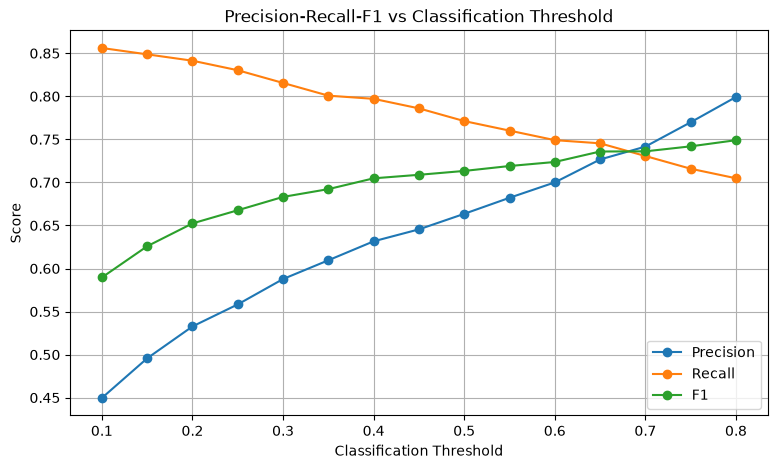

In [43]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall-F1 vs Classification Threshold")
plt.legend()
plt.grid()

plt.show()

Low threshold
      ↓
More machines classified Failure
      ↓
Recall ↑
Precision ↓


High threshold
      ↓
Fewer machines classified Failure
      ↓
Precision ↑
Recall ↓

In [44]:
threshold_results_fine = []

for threshold in np.arange(0.05, 0.951, 0.01):

    predictions = (oof_prob >= threshold).astype(int)

    threshold_results_fine.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

threshold_fine_df = pd.DataFrame(threshold_results_fine)

best_f1_row = threshold_fine_df.loc[
    threshold_fine_df["F1"].idxmax()
]

print("Best F1 threshold:")
print(best_f1_row)

Best F1 threshold:
Threshold    0.800000
Precision    0.799163
Recall       0.704797
F1           0.749020
Name: 75, dtype: float64


For predictive maintenance, I want us to explicitly compare the maximum-F1 threshold with a threshold that maintains at least 80% recall:

In [45]:
recall_candidates = threshold_fine_df[
    threshold_fine_df["Recall"] >= 0.80
]

best_high_recall = recall_candidates.loc[
    recall_candidates["Precision"].idxmax()
]

print("\nBest threshold with Recall >= 0.80:")
print(best_high_recall)


Best threshold with Recall >= 0.80:
Threshold    0.350000
Precision    0.609551
Recall       0.800738
F1           0.692185
Name: 30, dtype: float64


This gives us two defensible candidates:
Candidate A
Maximum F1
→ best statistical balance

Candidate B
Recall >= 80%
→ prioritizes detecting failures
   while maximizing precision under that constraint

The 80% recall constraint is a project design choice, not an industry safety standard.

Plot the fine-grained result

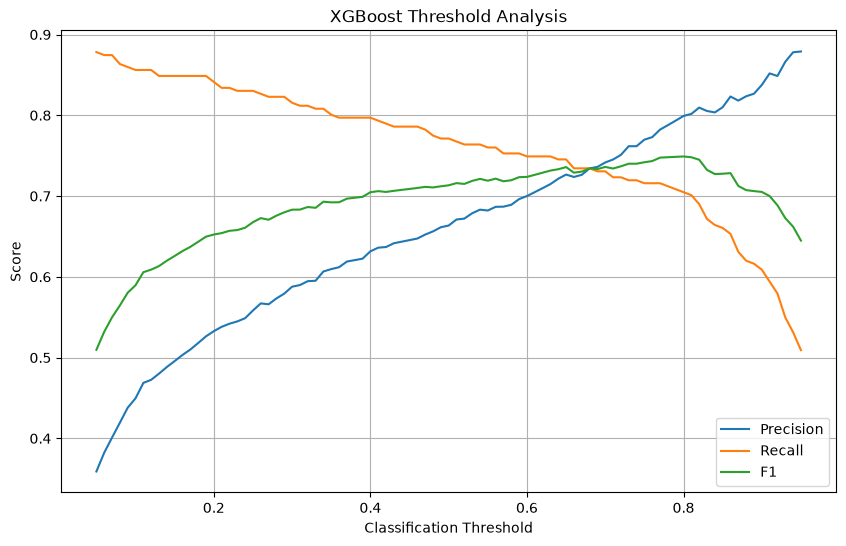

In [46]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_fine_df["Threshold"],
    threshold_fine_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_fine_df["Threshold"],
    threshold_fine_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_fine_df["Threshold"],
    threshold_fine_df["F1"],
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("XGBoost Threshold Analysis")
plt.legend()
plt.grid()
plt.show()

the above graph is very important 

One more improvement: use F2 score
For this particular project, F1 treats precision and recall equally. Since missing a developing failure can be more consequential than generating a false maintenance alert, it's useful to calculate an additional recall-weighted metric: F2.

In [47]:
from sklearn.metrics import fbeta_score

In [48]:
threshold_results_fine = []

for threshold in np.arange(0.05, 0.951, 0.01):

    predictions = (oof_prob >= threshold).astype(int)

    threshold_results_fine.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "F2": fbeta_score(
            y_train, predictions, beta=2,
            zero_division=0
        )
    })

threshold_fine_df = pd.DataFrame(threshold_results_fine)

In [49]:
best_f1 = threshold_fine_df.loc[
    threshold_fine_df["F1"].idxmax()
]

best_f2 = threshold_fine_df.loc[
    threshold_fine_df["F2"].idxmax()
]

print("Best F1 operating point:")
print(best_f1)

print("\nBest F2 operating point:")
print(best_f2)

Best F1 operating point:
Threshold    0.800000
Precision    0.799163
Recall       0.704797
F1           0.749020
F2           0.721844
Name: 75, dtype: float64

Best F2 operating point:
Threshold    0.290000
Precision    0.579221
Recall       0.822878
F1           0.679878
F2           0.759020
Name: 24, dtype: float64


Strategy	Threshold	Precision	Recall	F1	F2
Max F1	0.80	79.92%	70.48%	74.90%	72.18%
Max F2	0.29	57.92%	82.29%	67.99%	75.90%


For this predictive-maintenance prototype, I recommend freezing 0.29 as the alert threshold because our stated design priority is to reduce missed failures, and F2 explicitly weights recall more heavily. This is a project design choice, not a universal industrial threshold.
At 0.29, the cross-validated training behavior is approximately:
Detect 82.3% of failures, with 57.9% precision.

1. Freeze the configuration

In [50]:
FINAL_THRESHOLD = 0.29

print("Final classification threshold:", FINAL_THRESHOLD)

Final classification threshold: 0.29


Train final model on all 8,000 training records

In [51]:
best_xgb.fit(X_train, y_train)

print("Final XGBoost model trained successfully!")

Final XGBoost model trained successfully!


Finally unlock the test set

In [52]:
final_test_prob = best_xgb.predict_proba(X_test)[:, 1]

In [53]:
final_test_pred = (
    final_test_prob >= FINAL_THRESHOLD
).astype(int)

Calculate final metrics

In [54]:
final_accuracy = accuracy_score(
    y_test,
    final_test_pred
)

final_precision = precision_score(
    y_test,
    final_test_pred
)

final_recall = recall_score(
    y_test,
    final_test_pred
)

final_f1 = f1_score(
    y_test,
    final_test_pred
)

final_f2 = fbeta_score(
    y_test,
    final_test_pred,
    beta=2
)

final_roc_auc = roc_auc_score(
    y_test,
    final_test_prob
)

final_pr_auc = average_precision_score(
    y_test,
    final_test_prob
)

print("FINAL XGBOOST TEST RESULTS")
print("--------------------------------")

print("Threshold :", FINAL_THRESHOLD)
print("Accuracy  :", final_accuracy)
print("Precision :", final_precision)
print("Recall    :", final_recall)
print("F1 Score  :", final_f1)
print("F2 Score  :", final_f2)
print("ROC-AUC   :", final_roc_auc)
print("PR-AUC    :", final_pr_auc)

FINAL XGBOOST TEST RESULTS
--------------------------------
Threshold : 0.29
Accuracy  : 0.976
Precision : 0.6086956521739131
Recall    : 0.8235294117647058
F1 Score  : 0.7
F2 Score  : 0.7692307692307693
ROC-AUC   : 0.973876507124589
PR-AUC    : 0.8241793590220844


Get the final confusion matrix

In [55]:
final_cm = confusion_matrix(
    y_test,
    final_test_pred
)

print(final_cm)

tn, fp, fn, tp = final_cm.ravel()

print("\nTrue Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

[[1896   36]
 [  12   56]]

True Negatives : 1896
False Positives: 36
False Negatives: 12
True Positives : 56


 what this tell lets assume-
 Out of 68 actual failures:

TP = correctly detected failures
FN = failures our system missed

And out of 1932 healthy observations:

TN = correctly classified normal
FP = false maintenance alerts

Generate the classification report

In [56]:
print(
    classification_report(
        y_test,
        final_test_pred,
        target_names=[
            "Normal",
            "Failure"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.99      0.98      0.99      1932
     Failure       0.61      0.82      0.70        68

    accuracy                           0.98      2000
   macro avg       0.80      0.90      0.84      2000
weighted avg       0.98      0.98      0.98      2000



Plot confusion matrix professionally

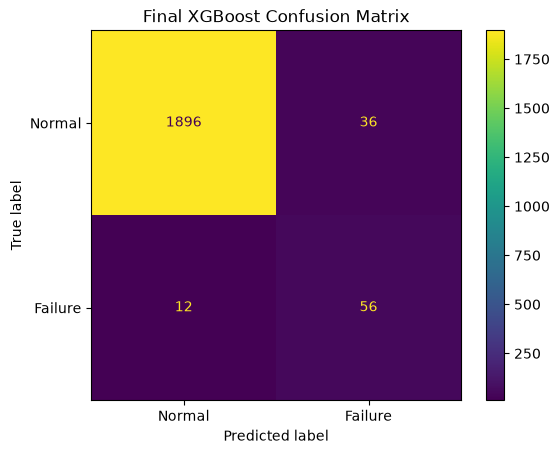

In [57]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=[
        "Normal",
        "Failure"
    ]
).plot()

plt.title(
    "Final XGBoost Confusion Matrix"
)

plt.show()

Plot Precision-Recall curve

In [58]:
from sklearn.metrics import precision_recall_curve

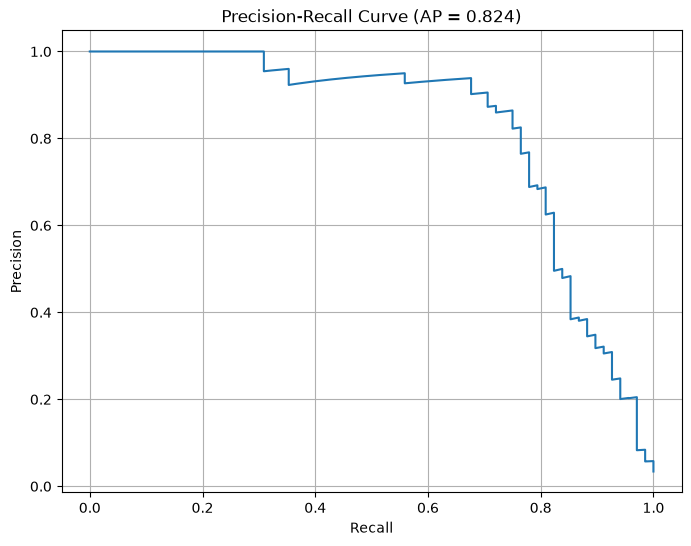

In [59]:
precision_curve, recall_curve, thresholds = (
    precision_recall_curve(
        y_test,
        final_test_prob
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    f"Precision-Recall Curve (AP = {final_pr_auc:.3f})"
)

plt.grid()

plt.show()

Also plot ROC curve

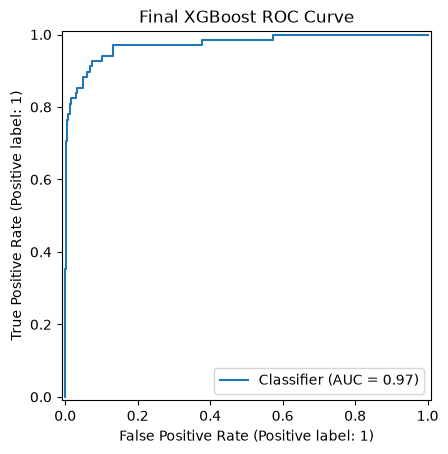

In [60]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    final_test_prob
)

plt.title("Final XGBoost ROC Curve")

plt.show()

This is a good final held-out result, especially given that failures are only 3.4% of the dataset.
Your final XGBoost system at the frozen 0.29 threshold achieved:
Class	Precision	Recall	F1	Samples
Normal	0.99	0.98	0.99	1932
Failure	0.61	0.82	0.70	68
Overall accuracy			0.98	2000


The most important number for our project is Failure Recall = 0.82. That means the model detects about 82% of previously unseen failure cases. Failure precision of 0.61 means that among observations flagged as failures, about 61% are actual failures. This is much more useful than the Dummy Classifier's 96.6% accuracy with zero failures detected.
Also, your cross-validation expectation was close to the final test behavior:
Training OOF at threshold 0.29:
Recall ≈ 82.29%

Final unseen test:
Recall ≈ 82%

That's encouraging evidence that the chosen operating point generalizes reasonably rather than collapsing on the held-out set.

Then save the complete pipeline:

In [63]:
joblib.dump(
    best_xgb,
    "../models/failure_xgboost.joblib"
)

print("Model saved successfully!")

Model saved successfully!


Save the threshold and metadata separately

In [64]:
model_config = {
    "model_name": "XGBoost Predictive Maintenance Classifier",
    "target": "Machine failure",
    "threshold": 0.29,

    "features": [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ],

    "excluded_leakage_features": [
        "TWF",
        "HDF",
        "PWF",
        "OSF",
        "RNF"
    ],

    "test_samples": 2000,
    "failure_samples_test": 68,

    "failure_precision": 0.61,
    "failure_recall": 0.82,
    "failure_f1": 0.70
}

with open(
    "../models/failure_model_config.json",
    "w"
) as file:
    json.dump(
        model_config,
        file,
        indent=4
    )

print("Model configuration saved successfully!")

Model configuration saved successfully!


Verify that the saved model actually works

In [65]:
loaded_model = joblib.load(
    "../models/failure_xgboost.joblib"
)

loaded_prob = loaded_model.predict_proba(
    X_test
)[:, 1]

loaded_pred = (
    loaded_prob >= 0.29
).astype(int)

print(
    classification_report(
        y_test,
        loaded_pred,
        target_names=["Normal", "Failure"]
    )
)

              precision    recall  f1-score   support

      Normal       0.99      0.98      0.99      1932
     Failure       0.61      0.82      0.70        68

    accuracy                           0.98      2000
   macro avg       0.80      0.90      0.84      2000
weighted avg       0.98      0.98      0.98      2000

